# Computation of Energy Distribution Function

## Imports

In [8]:
import ROOT, glob
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams['figure.dpi'] = 400
plt.rcParams['savefig.dpi'] = 400

## Load data

In [9]:
dirDir= "/home/users/l/lebrun/"
dataDir = "/dpnc/beegfs/dampe/tryf/MC_Skimmed/MC_gamma/"
figPath = dirDir + "figures/"
resultPath = dirDir + "results/"
dataPath = dirDir + "data/"
filename = dataDir + "DmlNtup_gamma_part000_TQ_FullSel.root"

# Find all matching ROOT files : from 1 GeV to 100 GeV
files = sorted(glob.glob(dataDir + "DmlNtup_gamma_part*_TQ_FullSel.root"))

# # Pass the list of files to RDataFrame
# rdf = ROOT.RDataFrame("DmlNtup", files)

# # Apply cut on LET
# rdf = rdf.Filter("tt_isLET == 1").Filter("theta_True < 60")

# # Extract only desired columns
# df = rdf.AsNumpy(["tt_ekin", "tt_bgoTotalEcorr_GeV", "theta_True", "tt_isHET", "tt_isLET"])
df = pd.read_csv(dataPath + "MC_let_filtered_energy.csv")
# Optional : exclude HET events
# df = df[df['tt_isHET'] == 0]

In [10]:

df['Etrue'] = df['tt_ekin'] * 1e-3
df = df[df['Etrue'] < 1e2]
df['Erec'] = df['tt_bgoTotalEcorr_GeV']

df['theta_True_deg']= df['theta_True']
df['theta_True'] = np.deg2rad(df['theta_True'])

df['cosTheta'] = np.cos(df['theta_True'])

## Compute energy deviation

In [11]:
df['Ediff'] = (df['Erec'] - df['Etrue'])/df['Etrue']
df['theta_True_deg'] = np.rad2deg(df['theta_True'])

In [12]:

print(f"Number of LET events: {len(df)}")

print(f"Max LET energy: {df['Etrue'].max()}")
print(f"Min LET energy: {df['Etrue'].min()}")

Number of LET events: 2353962
Max LET energy: 99.99975924540448
Min LET energy: 1.0014169282471725


In [13]:

Emin = 1
Emax = 100
n_E_bins = 4
E_bins_edge = np.logspace(np.log10(Emin), np.log10(Emax), n_E_bins + 1)
E_bins_center = np.sqrt(E_bins_edge[:-1] * E_bins_edge[1:])

print("E_bins :", E_bins_center)
print("E_bins_edge :", E_bins_edge)

cos_theta_min = 0.5
cos_theta_max = 1
n_theta_bins = 5
theta_bins_edge = np.linspace(cos_theta_min, cos_theta_max, n_theta_bins + 1)
theta_bins_center = (theta_bins_edge[:-1] + theta_bins_edge[1:])/2

print("theta_bins :", theta_bins_center)
print("theta_bins_edge :", theta_bins_edge)

print("Emin: ", Emin)
print("Emax: ", Emax)
print("cos theta_min: ", cos_theta_min)
print("cos theta_max: ", cos_theta_max)

n_Ediff_bins = 100
Ediff_min = df['Ediff'].min()
Ediff_max = df['Ediff'].max()
Ediff_bins = np.linspace(Ediff_min, Ediff_max, n_Ediff_bins + 1)

# Assign bin indices
df['E_bin'] = pd.cut(df['Etrue'], bins=E_bins_edge, labels=False, include_lowest=True)
df['theta_bin'] = pd.cut(df['cosTheta'], bins=theta_bins_edge, labels=False, include_lowest=True)

# Drop rows that fall outside the bins (e.g., NaN bin index)
df = df.dropna(subset=['E_bin', 'theta_bin']).copy() # Copy to avoid SettingWithCopyWarning

# Make sure bin indices are integers
df['E_bin'] = df['E_bin'].astype(int)
df['theta_bin'] = df['theta_bin'].astype(int)

# Group by (E_bin, theta_bin)
grouped = df.groupby(['E_bin', 'theta_bin'])

# Apply resolution calculation : HBW of 68% containment interval 
resolution_per_bin = grouped['Ediff'].apply(
    lambda x: 0.5 * (np.percentile(x, 84) - np.percentile(x, 16))
).reset_index(name='resolution')

print(resolution_per_bin.head())

# Step 4: Merge back into original dataframe
if 'resolution' in df.columns:
    df = df.drop(columns='resolution')
df = df.merge(resolution_per_bin, on=['E_bin', 'theta_bin'], how='left')
print(df.head())


E_bins : [ 1.77827941  5.62341325 17.7827941  56.23413252]
E_bins_edge : [  1.           3.16227766  10.          31.6227766  100.        ]
theta_bins : [0.55 0.65 0.75 0.85 0.95]
theta_bins_edge : [0.5 0.6 0.7 0.8 0.9 1. ]
Emin:  1
Emax:  100
cos theta_min:  0.5
cos theta_max:  1
   E_bin  theta_bin  resolution
0      0          0    0.040911
1      0          1    0.038195
2      0          2    0.035223
3      0          3    0.033354
4      0          4    0.032227
   tt_bgoTotalEcorr_GeV  tt_isLET  tt_isHET       tt_ekin  theta_True  \
0             51.234132       1.0       0.0  51479.672419    0.241034   
1              8.801922       1.0       0.0   8846.751369    0.281603   
2              3.910873       1.0       1.0   4144.790656    0.669844   
3             83.132685       1.0       1.0  81787.508280    0.222307   
4              4.155001       1.0       1.0   4193.699621    0.698137   

       Etrue       Erec  theta_True_deg  cosTheta     Ediff  E_bin  theta_bin  \
0  51.

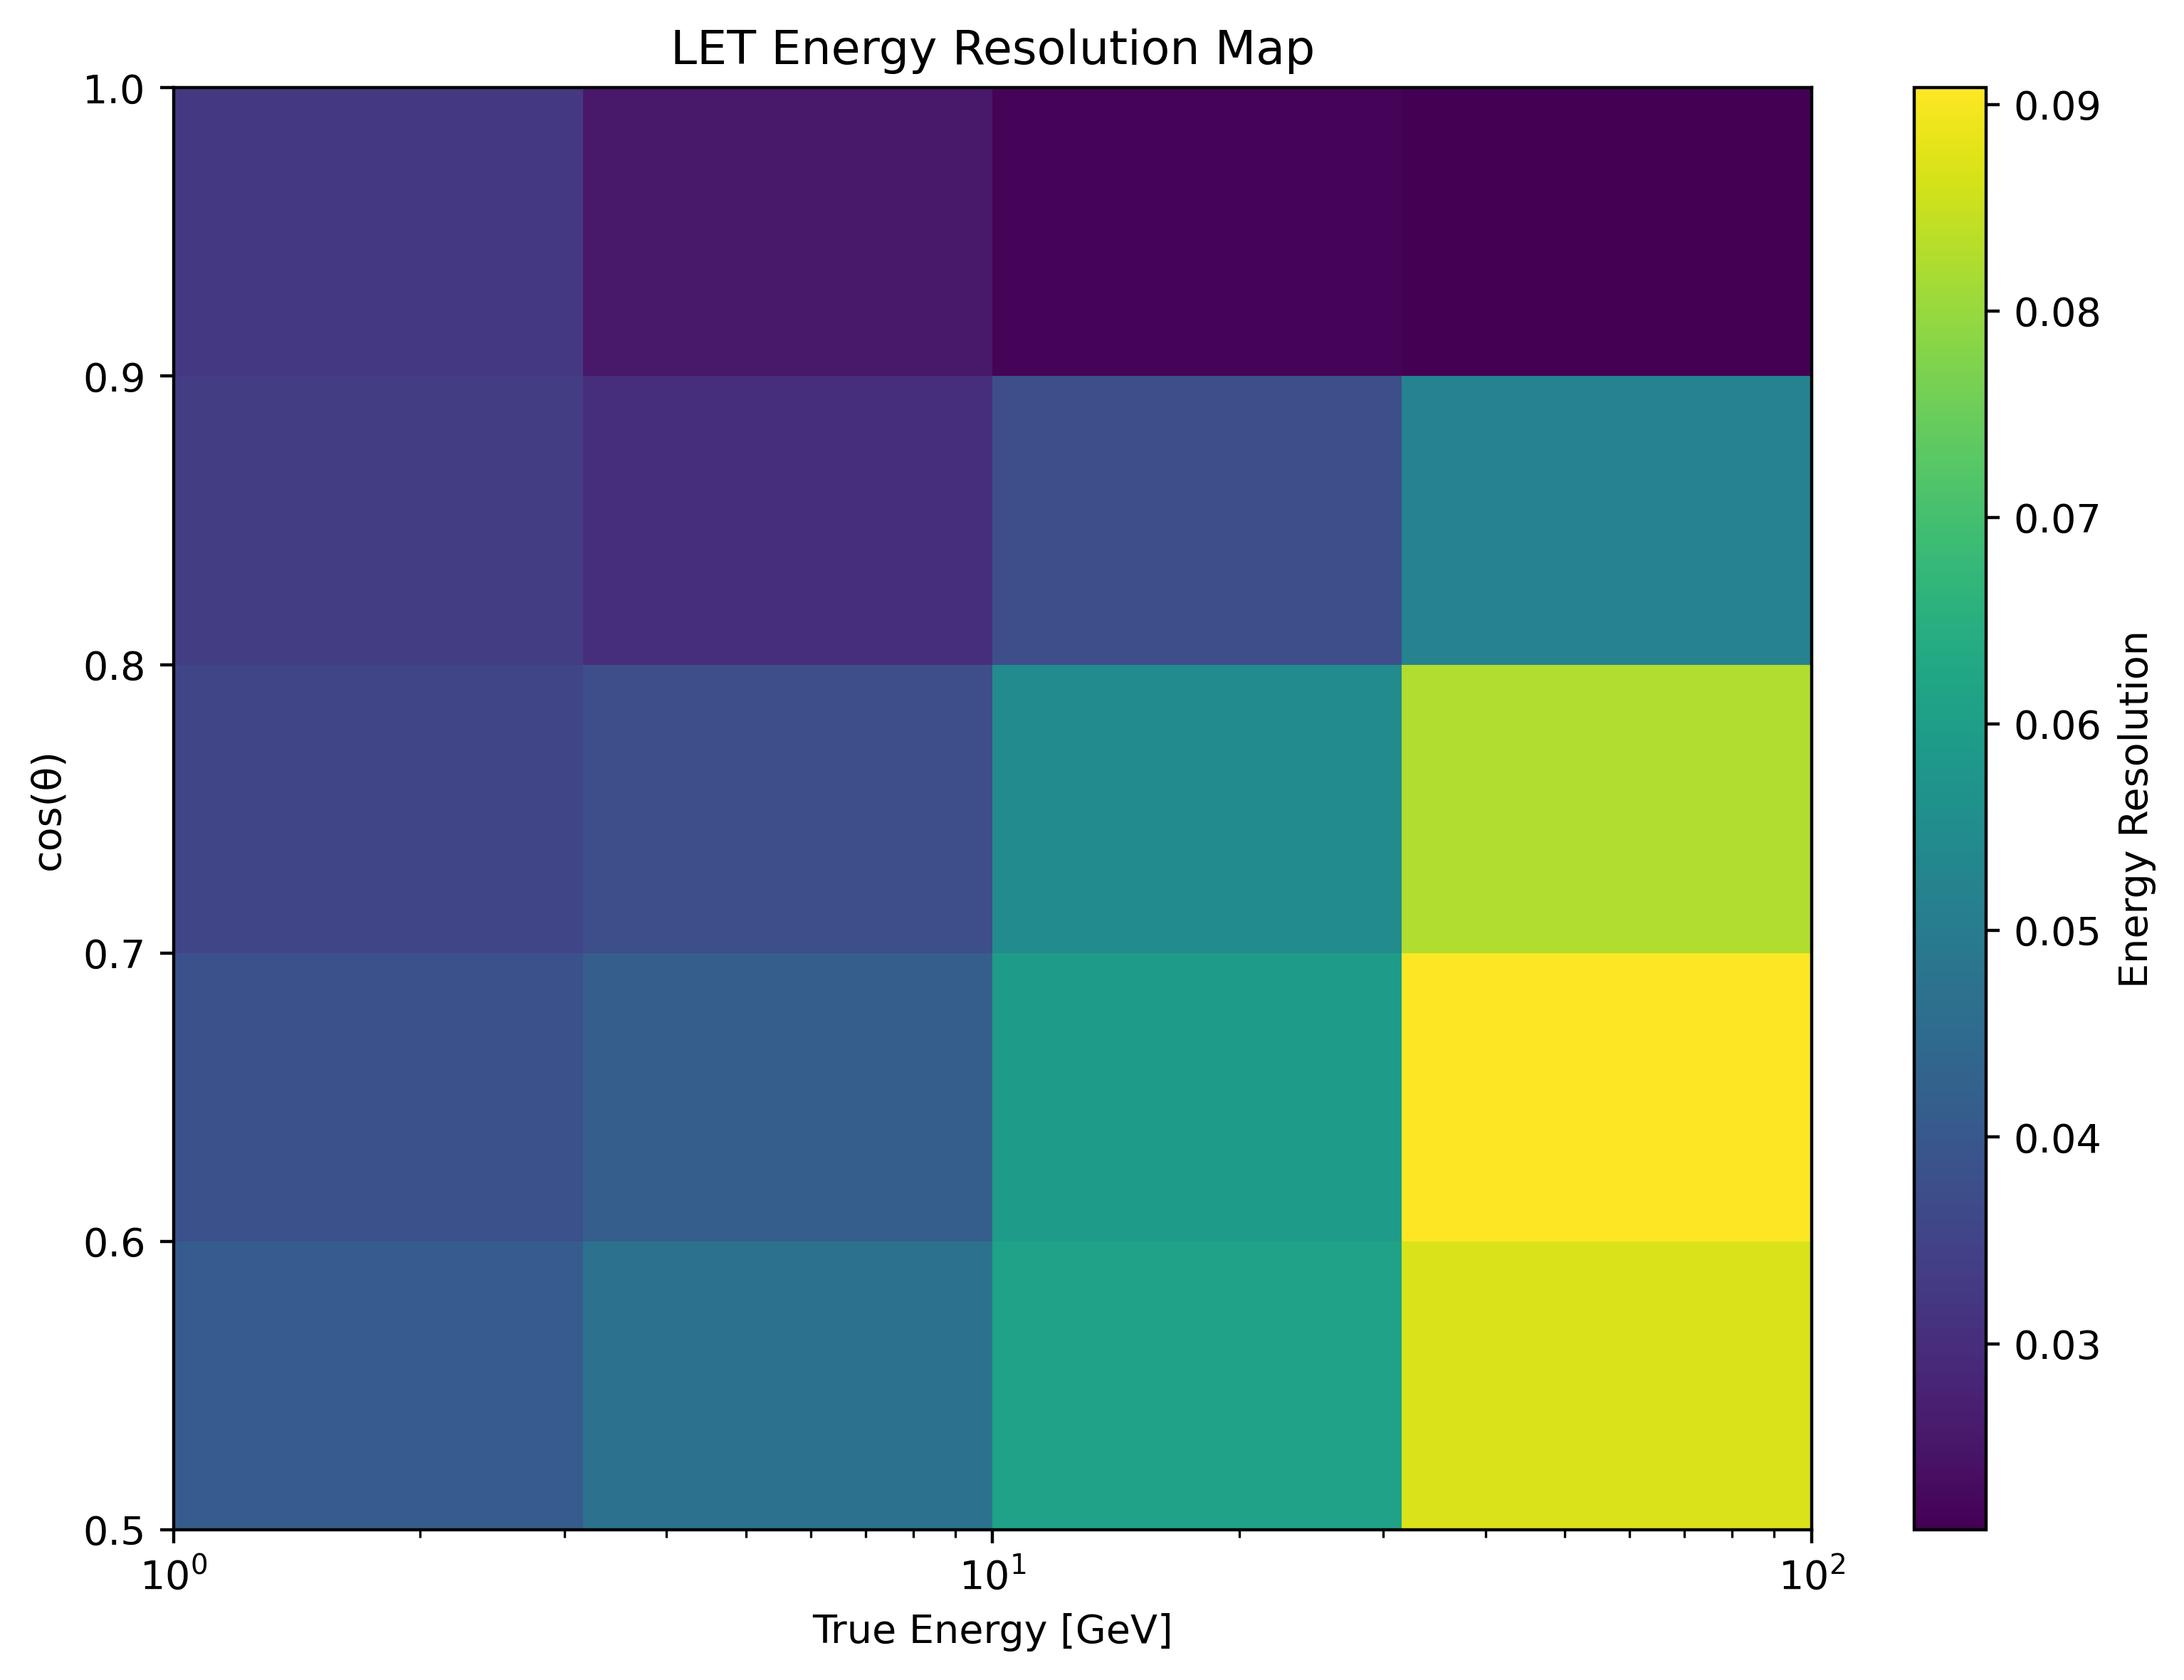

In [14]:
# Build the resolution grid directly
resolution_grid = np.full((n_E_bins, n_theta_bins), np.nan)
for _, row in resolution_per_bin.iterrows():
    resolution_grid[int(row['E_bin']), int(row['theta_bin'])] = row['resolution']


# Prepare edges for pcolormesh
E_edges = E_bins_edge

# Plot
fig, ax = plt.subplots(figsize=(8, 6))
c = ax.pcolormesh(E_edges, theta_bins_edge, resolution_grid.T, shading='auto', cmap='viridis')

# Log scale for energy
ax.set_xscale('log')
ax.set_xlabel("True Energy [GeV]")
ax.set_ylabel("cos(θ)")
ax.set_title("LET Energy Resolution Map")

# Colorbar
cb = fig.colorbar(c, ax=ax)
cb.set_label("Energy Resolution")

plt.tight_layout()
fig.savefig(figPath + "LET_Energy_Resolution_Map.png", dpi=400)
plt.show()


### CONCLUSION
- Better resolution (lower values) when HET + LET considered
- Expected a minimum at higher energy ? Not the case

## Save map for future use 

In [15]:
np.savez_compressed(
    resultPath + "energy_resolution_grid_LET.npz",
    resolution_grid=resolution_grid,
    E_bins_edge=E_bins_edge,
    theta_bins_edge=theta_bins_edge
)

## Compute scaled energy deviation

In [16]:
df['x_D'] = df['Ediff'] / df['resolution']

## Plot x_D

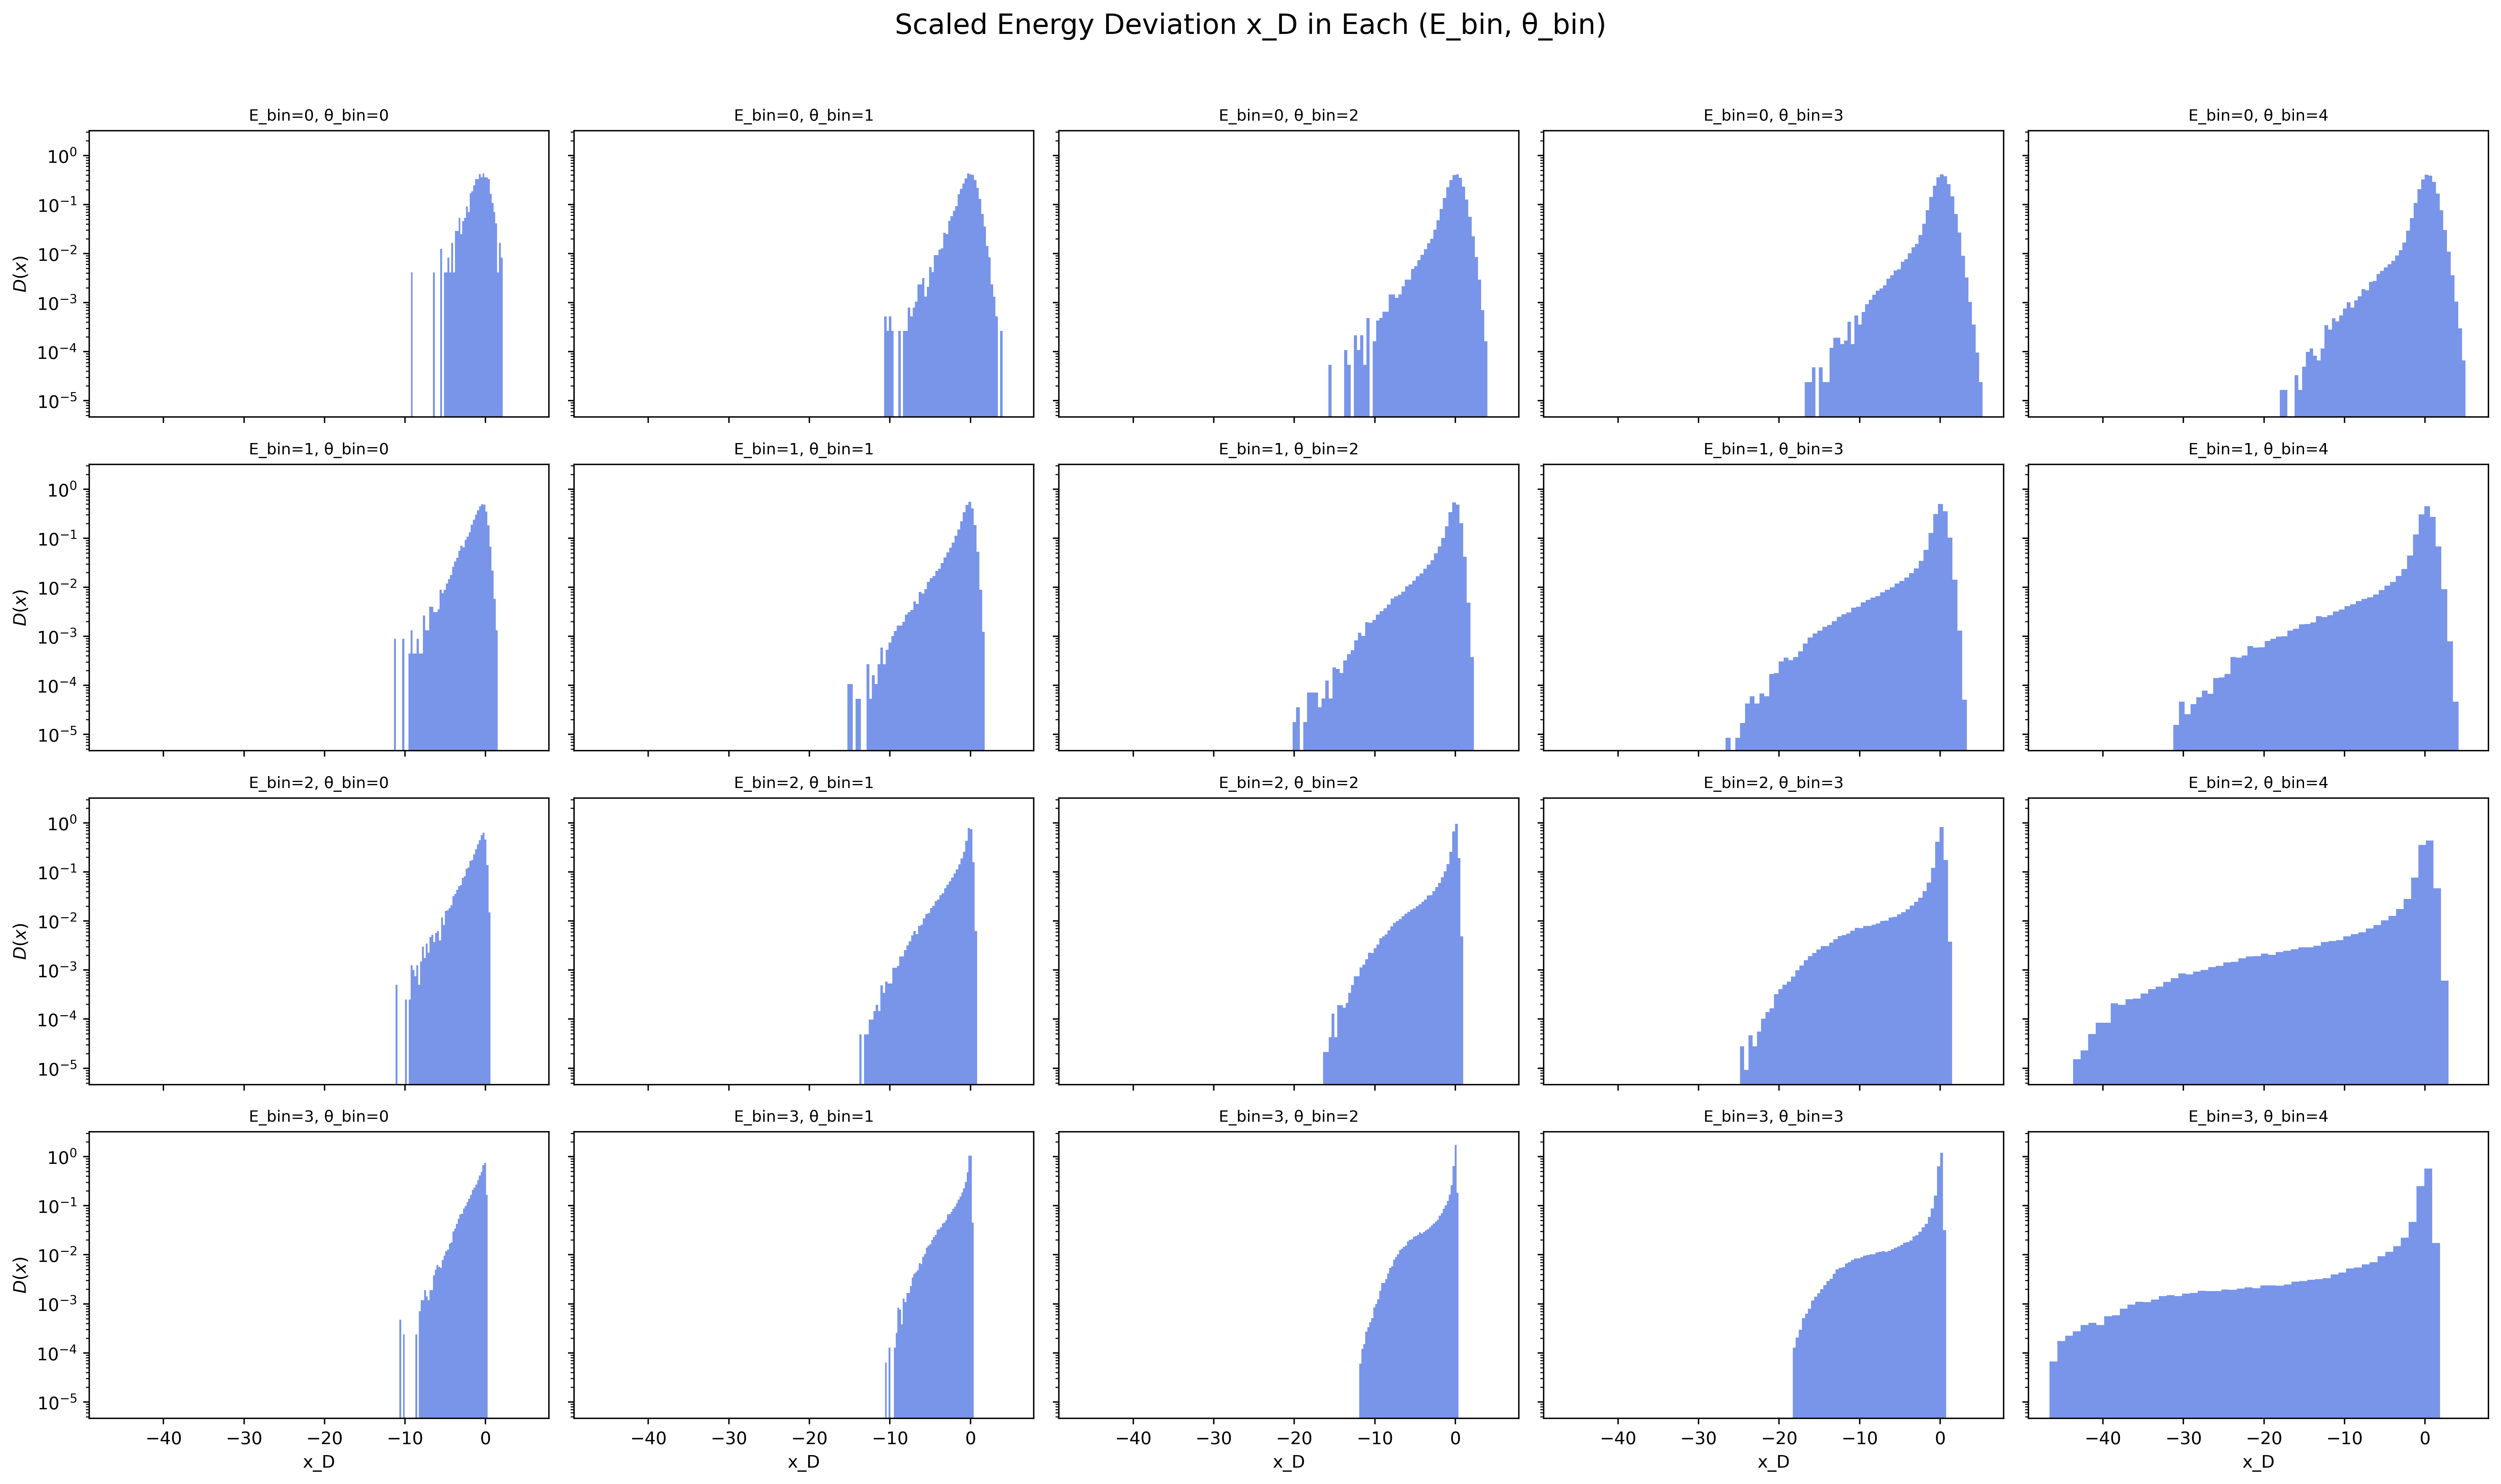

In [17]:
# Plot x_D for all 20 E, theta bins
# Determine subplot grid size
n_rows = n_E_bins
n_cols = n_theta_bins

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 4, n_rows * 3), sharex=True, sharey=True)
fig.suptitle("Scaled Energy Deviation x_D in Each (E_bin, θ_bin)", fontsize=16)

# Plot each bin
for i in range(n_E_bins):
    for j in range(n_theta_bins):
        ax = axes[i, j]
        subset = df[(df['E_bin'] == i) & (df['theta_bin'] == j)]

        if not subset.empty:
            ax.hist(subset['x_D'], bins=50, color='royalblue', alpha=0.7, density=True)
            ax.set_title(f"E_bin={i}, θ_bin={j}", fontsize=9)
        else:
            ax.set_visible(False)

        if i == n_rows - 1:
            ax.set_xlabel("x_D")
        if j == 0:
            ax.set_ylabel("$D(x)$")
        ax.set_yscale('log')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## Fit with Fermi's functions

In [18]:
from scipy.special import gamma
from scipy.stats import chi2

def asymetric_gaussian(x, sigma, k, b, p):
    factorK = k / (1 + k**2)
    factorP = p / (sigma * gamma(1 / p))
    gaus = np.where(
        x - b >= 0,
        np.exp(-(k * np.abs(x - b) / sigma)**p),
        np.exp(-((np.abs(x - b) / (sigma * k))**p))
    )
    return factorK * factorP * gaus

# Define the full fit model
def fitDensity(x, F, sigma1, k1, b1, p1, sigma2, k2, b2, p2):
    return (
        F * asymetric_gaussian(x, sigma1, k1, b1, p1) +
        (1 - F) * asymetric_gaussian(x, sigma2, k2, b2, p2)
    )

def chisq(data, model, error, dofs):
    residuals = np.abs(data - model)
    chi_squared = np.sum((residuals)**2 / (error**2))
    p_value = 1 - chi2.cdf(chi_squared, dofs)
    return chi_squared, p_value


In [19]:
from scipy.optimize import curve_fit
# Select a specific bin (E_bin and theta_bin)
E_bin = 0
theta_bin = 1
n_bins = 100
subset = df[(df['E_bin'] == E_bin) & (df['theta_bin'] == theta_bin) & (df['x_D'] > -15)] 
counts, bin_edges = np.histogram(subset['x_D'], bins=n_bins)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
bin_widths = bin_edges[1:] - bin_edges[:-1]
errors = np.sqrt(counts)

# Normalize counts and errors
total = np.sum(counts)
counts_norm = counts / (bin_widths * total) # TODO: check if this is correct
errors_norm = errors / (bin_widths * total)

# ---- Initial guesses ----
F_init = 0.5
mean = np.average(subset['x_D'])
std = np.std(subset['x_D'])

print(f"Numbers of bins under 5 counts threshold : {len(counts[counts < 5])}")

threshold = 5e-3 * np.max(counts)

# Mask: counts > 5 and density > 10⁻3
mask = (counts > threshold) & (counts_norm > 0.001) & (errors_norm < 0.5*counts_norm)
bin_centers_masked = bin_centers[mask]
print("Number of bins remaining after mask :", len(bin_centers_masked))
counts_norm_masked = counts_norm[mask]
errors_norm_masked = errors_norm[mask]

# Updated initial guesses
mean = np.average(subset['x_D'])
std = np.std(subset['x_D'])
p0 = [
    0.5,        # F
    std / 2, 1.0, mean - std/2, 2.0,  # sigma1, k1, b1, p1
    std,     1.0, mean + std/2, 2.0   # sigma2, k2, b2, p2
]

# Bounds: to constrain parameters to physical values
bounds = (
    [0,   1e-3, 0.1, mean - 3*std, 0.5,  1e-3, 0.1, mean - std, 0.5],   # Lower bounds
    [1,   10.0, 10.0, mean,       10.0, 10.0, 10.0, mean + 3*std, 10.0]  # Upper bounds
)

# Fit
try:
    popt, pcov = curve_fit(
        fitDensity,
        bin_centers_masked,
        counts_norm_masked,
        p0=p0,
        sigma=errors_norm_masked,
        bounds=bounds,
        absolute_sigma=True,
        maxfev=20000
    )
except RuntimeError as e:
    print("Fit failed:", e)
    popt = None

# Compute expected values from fit
fit_vals = fitDensity(bin_centers_masked, *popt)
fit_vals_counts = fit_vals * (bin_widths[mask] * total)  # Convert back to counts

F, sigma1, k1, b1, p1, sigma2, k2, b2, p2 = popt
print("F:", F, "bounds:", bounds[0][0], bounds[1][0])
print("sigma1:", sigma1, "bounds:", bounds[0][1], bounds[1][1])
print("k1:", k1, "bounds:", bounds[0][2], bounds[1][2])
print("b1:", b1, "bounds:", bounds[0][3], bounds[1][3])
print("p1:", p1, "bounds:", bounds[0][4], bounds[1][4])
print("sigma2:", sigma2, "bounds:", bounds[0][5], bounds[1][5])
print("k2:", k2, "bounds:", bounds[0][6], bounds[1][6])
print("b2:", b2, "bounds:", bounds[0][7], bounds[1][7])
print("p2:", p2, "bounds:", bounds[0][8], bounds[1][8])


# Compute chi-squared
ndof = len(bin_centers_masked) - len(popt)  # number of degrees of freedom
chi_squared, p_val = chisq(counts[mask], fit_vals_counts, errors[mask], ndof)
chi_squared_str = f"$\chi^2$/ndof = {chi_squared:.2f}/{ndof} = {chi_squared/ndof:.2f}"

Numbers of bins under 5 counts threshold : 43
Number of bins remaining after mask : 57
F: 0.3415525783952867 bounds: 0 1
sigma1: 0.9215913833131624 bounds: 0.001 10.0
k1: 0.9294856937869378 bounds: 0.1 10.0
b1: -0.3455070993596659 bounds: -3.9137550242222074 -0.3455070963962383
p1: 1.5165440084877775 bounds: 0.5 10.0
sigma2: 1.110926234103216 bounds: 0.001 10.0
k2: 1.631578910419389 bounds: 0.1 10.0
b2: 0.4535651468907298 bounds: -1.5349230723382281 3.2227408314297312
p2: 1.3425927884308724 bounds: 0.5 10.0


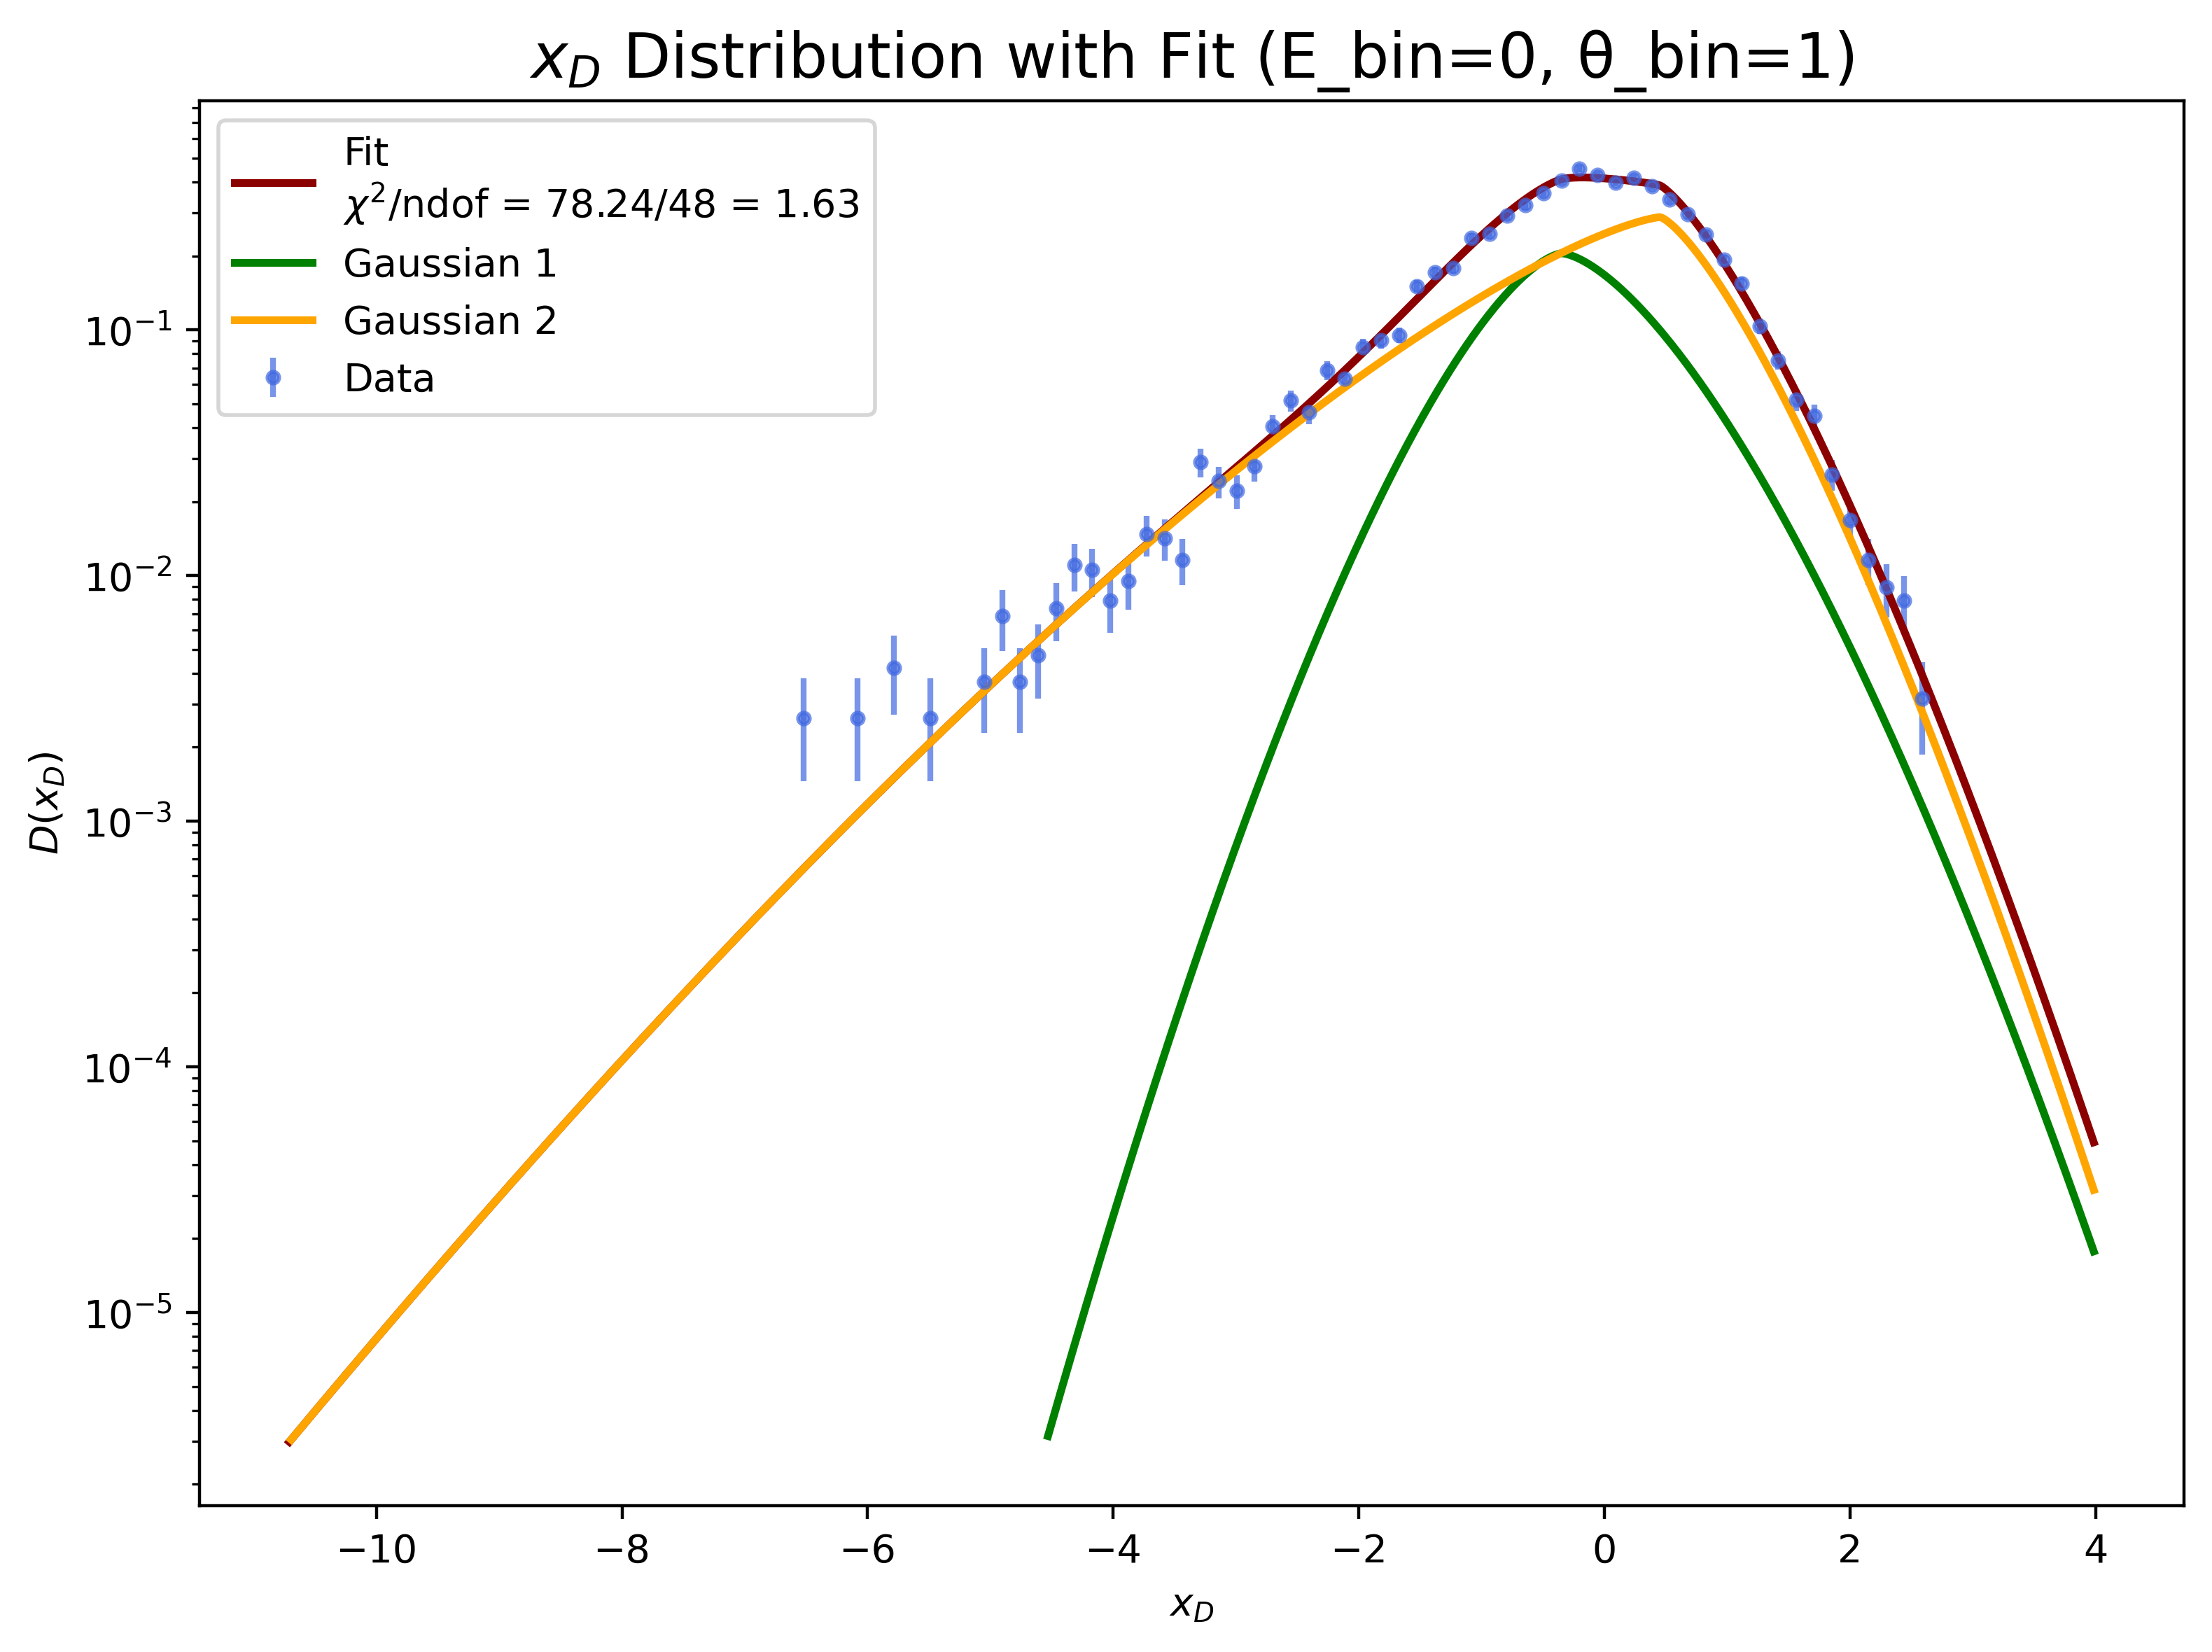

In [20]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.errorbar(bin_centers_masked, counts_norm_masked, yerr=errors_norm_masked, fmt='o', color='royalblue', alpha=0.7, label="Data", markersize=3)

if popt is not None:
    x_fit = np.linspace(bin_edges[0], bin_edges[-1], 1000)
    y_fit = fitDensity(x_fit, *popt)
    ax.plot(x_fit, y_fit, color='darkred', lw=2, label=f'Fit\n{chi_squared_str}')
    F, sigma1, k1, b1, p1, sigma2, k2, b2, p2 = popt
    y_fit1 = F * asymetric_gaussian(x_fit, sigma1, k1, b1, p1)
    y_fit2 = (1 - F) * asymetric_gaussian(x_fit, sigma2, k2, b2, p2)
    # Create masks for each Gaussian component based on the condition
    mask1 = y_fit1 > np.min(y_fit)  # Gaussian 1 condition: x - b1 >= 0
    mask2 = y_fit2 > np.min(y_fit)   # Gaussian 2 condition: x - b2 < 0

    # Apply the masks to plot only the regions where the conditions are satisfied
    ax.plot(x_fit[mask1], y_fit1[mask1], color='green', lw=2, label='Gaussian 1')
    ax.plot(x_fit[mask2], y_fit2[mask2], color='orange', lw=2, label='Gaussian 2')

ax.set_title(f"$x_D$ Distribution with Fit (E_bin={E_bin}, θ_bin={theta_bin})", fontsize=16)
ax.set_xlabel("$x_D$")
ax.set_ylabel("$D(x_D)$")
ax.set_yscale('log')
ax.legend()
plt.tight_layout()
plt.show()

## Try with Chinese people function

In [21]:
def R(x, x0, sigma, gamma):
    return np.exp(-0.5 * np.abs((x - x0) / sigma)**gamma)

def D(x, x0, xbarL, xbarR, sigmaL, gammaL, sigmaI, gammaI, sigmaR, gammaR, N):
    # Piecewise evaluation
    D_vals = np.zeros_like(x)
    mask_L = x - x0 < xbarL
    mask_I = (x - x0 >= xbarL) & (x - x0 <= xbarR)
    mask_R = x - x0 > xbarR

    NL = N * R(xbarL, x0, sigmaI, gammaI) / R(xbarL, x0, sigmaL, gammaL)
    NR = N * R(xbarR, x0, sigmaI, gammaI) / R(xbarR, x0, sigmaR, gammaR)

    D_vals[mask_L] = NL * R(x[mask_L], x0, sigmaL, gammaL)
    D_vals[mask_I] = N * R(x[mask_I], x0, sigmaI, gammaI)
    D_vals[mask_R] = NR * R(x[mask_R], x0, sigmaR, gammaR)

    return D_vals

### First step : fit with all degrees of freedom (first guess)

In [22]:
def curve_fit_custom(*args, tol=0.05, **kwargs):
    # Run curve fitting
    popt, pcov = curve_fit(*args, **kwargs)

    # Warn if near bounds
    if "bounds" in kwargs:
        lower_bounds, upper_bounds = kwargs["bounds"]
        for i, par in enumerate(popt):
            lb, ub = lower_bounds[i], upper_bounds[i]
            if np.isfinite(lb) and lb != 0:
                if np.abs(par - lb) < tol * np.abs(lb):
                    print(f"WARNING: Parameter {i} = {par:.4g} is within {tol*100:.1f}% of its lower bound ({lb})")
            if np.isfinite(ub) and ub != 0:
                if np.abs(par - ub) < tol * np.abs(ub):
                    print(f"WARNING: Parameter {i} = {par:.4g} is within {tol*100:.1f}% of its upper bound ({ub})")
    
    return popt, pcov

def random_walk_fit(model, x, y, yerr, p0, bounds, norm_array, n_trials=30, noise_scale=0.1, verbose=False):
    best_popt = None
    best_chi2 = np.inf
    best_fit_vals = None

    lower_bounds, upper_bounds = bounds

    for trial in range(n_trials):
        p0_perturbed = []
        for i, p in enumerate(p0):
            if p != 0:
                perturbed = p * (1 + noise_scale * np.random.uniform(-1, 1))
            else:
                perturbed = noise_scale * np.random.randn()

            # Clip to stay within bounds
            perturbed = np.clip(perturbed, lower_bounds[i], upper_bounds[i])
            p0_perturbed.append(perturbed)

        try:
            popt, pcov = curve_fit(
                model,
                x,
                y,
                p0=p0_perturbed,
                sigma=yerr,
                bounds=bounds,
                absolute_sigma=True,
                maxfev=30000
            )
            fit_vals = model(x, *popt)
            fit_vals_counts = fit_vals * norm_array  # Convert back to counts
            counts = y * norm_array  # Convert back to counts
            yerr_counts = yerr * norm_array  # Convert back to counts
            chi2_val, p_val = chisq(counts, fit_vals_counts, yerr_counts, len(x) - len(popt))
            #np.sum((y - fit_vals) ** 2 / (yerr ** 2))

            if chi2_val < best_chi2:
                best_chi2 = chi2_val
                best_popt = popt
                best_fit_vals = fit_vals

            if verbose:
                print(f"Trial {trial}: χ² = {chi2_val:.2f}")

        except RuntimeError:
            if verbose:
                print(f"Trial {trial}: Fit failed.")
            continue

    return best_popt, best_fit_vals, best_chi2

def random_start_random_walk_fit(
    model, x, y, yerr, bounds, norm_array, n_trials=30, noise_scale=0.1, verbose=False
):
    # Generate random starting points within bounds
    lower_bounds, upper_bounds = bounds
    p0_randoms = []
    # Generate n_trials random starting points
    for _ in range(n_trials):
        p0_random = []
        for i in range(len(lower_bounds)):
            if np.isfinite(lower_bounds[i]) and np.isfinite(upper_bounds[i]):
                p0_random.append(np.random.uniform(lower_bounds[i], upper_bounds[i]))
            else:
                p0_random.append(np.random.randn())  # Random value if bounds are not finite
        p0_randoms.append(p0_random)
    best_popt = None
    best_chi2 = np.inf
    best_fit_vals = None
    for p0 in p0_randoms:
        try:
            _popt, _fit_vals, _chi2 = random_walk_fit(
                model,
                x,
                y,
                yerr,
                p0,
                bounds,
                norm_array,
                n_trials=30,
                noise_scale=noise_scale,
                verbose=verbose
            )

            if _chi2 < best_chi2:
                best_chi2 = _chi2
                best_popt = _popt
                best_fit_vals = _fit_vals
                if verbose:
                    print(f"New best parameters: {best_popt}")
                    print(f"New best fit values: {best_fit_vals}")
                    print(f"New best χ²: {_chi2:.2f}")
                else: 
                    print(f"New best value : χ² = {_chi2:.2f}")

        except RuntimeError:
            if verbose:
                print("Fit failed.")
            continue
        except ValueError:
            if verbose:
                print("ValueError in fit.")
            continue
    

    return best_popt, best_fit_vals, best_chi2


In [23]:


# --- Initial Guesses ---
x0_guess = bin_centers[np.argmax(counts_norm)]
xbarL_guess = -10.01  # reasonable empirical cutoff
xbarR_guess = -0.2  # reasonable empirical cutoff
# p0 = [
#     x0_guess, xbarL_guess, xbarR_guess,  # x0, xbarL
#     0.4, 1.5,   # sigmaL, gammaL
#     0.4, 2.0,   # sigmaI, gammaI
#     0.4, 1.5,   # sigmaR, gammaR
#     1.0, 1.0, 1.0  # NL, NI, NR
# ]

p0 = [
    x0_guess, xbarL_guess, xbarR_guess,  # x0, xbarL
    7.54, 1.86,   # sigmaL, gammaL
    0.4, 2.0,   # sigmaI, gammaI
    0.4, 1.5,   # sigmaR, gammaR
    1.0  # N
]

# --- Bounds (to ensure positive widths and normalizations) ---
#   x0, xbarL, xbarR, sigmaL, gammaL, sigmaI, gammaI, sigmaR, gammaR, NL, NI, NR
bounds = (
    [-20, -15, -3,  0.001, 0.01,  1e-8, 0.01,  0.01, 0.4,  0],
    [ 20, 0, 1,  13,  10,  6, 10, 6, 10, 100]
)

norm_array = bin_widths[mask] * total

# Fit
try:
    popt, fit_vals, chi_squared = random_start_random_walk_fit(
    D,
    bin_centers_masked,
    counts_norm_masked,
    errors_norm_masked,
    bounds,
    norm_array,
    noise_scale=0.2,  # Increase if still stuck
    verbose=False,
    n_trials=100,  # Increase if still stuck
)

except RuntimeError as e:
    print("Fit failed:", e)
    popt = None

print(popt)

x0, xbarL, xbarR, sigmaL, gammaL, sigmaI, gammaI, sigmaR, gammaR, N = popt
NL = N * R(xbarL, x0, sigmaI, gammaI) / R(xbarL, x0, sigmaL, gammaL)
NR = N * R(xbarR, x0, sigmaI, gammaI) / R(xbarR, x0, sigmaR, gammaR)

print(f"Fit parameters:")
print(f"x0: {x0}, xbarL: {xbarL}, xbarR: {xbarR}")
print(f"sigmaL: {sigmaL}, gammaL: {gammaL}")
print(f"sigmaI: {sigmaI}, gammaI: {gammaI}")
print(f"sigmaR: {sigmaR}, gammaR: {gammaR}")
print(f"NL: {NL}, NI: {N}, NR: {NR}")


# Compute chi-squared

ndof = len(bin_centers_masked) - len(popt)  # number of degrees of freedom
p_value = 1 - chi2.cdf(chi_squared, ndof)

chi_squared_str = f"$\chi^2$/ndof = {chi_squared:.2f}/{ndof} = {chi_squared/ndof:.2f}"
print(f"P-value : ", p_value)
if p_value < 1e-16:
    prob_str = "p-value < 1e-16"
else:
    prob_str = f"p-value = {p_value:.2g}"

New best value : χ² = 12883.00


/tmp/ipykernel_274178/249257967.py:11: RuntimeWarning: invalid value encountered in scalar divide
  NL = N * R(xbarL, x0, sigmaI, gammaI) / R(xbarL, x0, sigmaL, gammaL)
/tmp/ipykernel_274178/249257967.py:11: RuntimeWarning: divide by zero encountered in scalar divide
  NL = N * R(xbarL, x0, sigmaI, gammaI) / R(xbarL, x0, sigmaL, gammaL)
/tmp/ipykernel_274178/249257967.py:12: RuntimeWarning: divide by zero encountered in scalar divide
  NR = N * R(xbarR, x0, sigmaI, gammaI) / R(xbarR, x0, sigmaR, gammaR)
/tmp/ipykernel_274178/249257967.py:16: RuntimeWarning: invalid value encountered in multiply
  D_vals[mask_R] = NR * R(x[mask_R], x0, sigmaR, gammaR)
/cvmfs/sft.cern.ch/lcg/views/LCG_107/x86_64-el9-gcc14-opt/lib/python3.11/site-packages/scipy/optimize/_lsq/common.py:141: RuntimeWarning: invalid value encountered in scalar multiply
  alpha = max(0.001 * alpha_upper, (alpha_lower * alpha_upper)**0.5)
/cvmfs/sft.cern.ch/lcg/views/LCG_107/x86_64-el9-gcc14-opt/lib/python3.11/site-packages/sc

New best value : χ² = 10049.80


/tmp/ipykernel_274178/249257967.py:12: RuntimeWarning: overflow encountered in scalar divide
  NR = N * R(xbarR, x0, sigmaI, gammaI) / R(xbarR, x0, sigmaR, gammaR)
/tmp/ipykernel_274178/249257967.py:14: RuntimeWarning: invalid value encountered in multiply
  D_vals[mask_L] = NL * R(x[mask_L], x0, sigmaL, gammaL)


New best value : χ² = 250.34


/cvmfs/sft.cern.ch/lcg/views/LCG_107/x86_64-el9-gcc14-opt/lib/python3.11/site-packages/scipy/optimize/_lsq/common.py:115: RuntimeWarning: overflow encountered in power
  phi_prime = -np.sum(suf ** 2 / denom**3) / p_norm
/cvmfs/sft.cern.ch/lcg/views/LCG_107/x86_64-el9-gcc14-opt/lib/python3.11/site-packages/scipy/optimize/_lsq/common.py:154: RuntimeWarning: divide by zero encountered in scalar divide
  ratio = phi / phi_prime
/cvmfs/sft.cern.ch/lcg/views/LCG_107/x86_64-el9-gcc14-opt/lib/python3.11/site-packages/scipy/optimize/_lsq/common.py:115: RuntimeWarning: invalid value encountered in scalar divide
  phi_prime = -np.sum(suf ** 2 / denom**3) / p_norm


New best value : χ² = 74.90


/tmp/ipykernel_274178/249257967.py:11: RuntimeWarning: overflow encountered in scalar divide
  NL = N * R(xbarL, x0, sigmaI, gammaI) / R(xbarL, x0, sigmaL, gammaL)


New best value : χ² = 65.78


/cvmfs/sft.cern.ch/lcg/views/LCG_107/x86_64-el9-gcc14-opt/lib/python3.11/site-packages/scipy/optimize/_lsq/common.py:166: RuntimeWarning: divide by zero encountered in scalar divide
  p *= Delta / norm(p)
/cvmfs/sft.cern.ch/lcg/views/LCG_107/x86_64-el9-gcc14-opt/lib/python3.11/site-packages/scipy/optimize/_lsq/common.py:166: RuntimeWarning: invalid value encountered in multiply
  p *= Delta / norm(p)
/cvmfs/sft.cern.ch/lcg/views/LCG_107/x86_64-el9-gcc14-opt/lib/python3.11/site-packages/scipy/optimize/_minpack_py.py:542: RuntimeWarning: overflow encountered in multiply
  return transform * (func(xdata, *params) - ydata)


New best value : χ² = 65.43
[-0.04247043 -1.62898545  0.75312424  0.17993762  0.74080726  0.86762999
  1.61167804  0.54366605  1.492028    0.43636014]
Fit parameters:
x0: -0.042470429711371736, xbarL: -1.6289854488629618, xbarR: 0.753124241424613
sigmaL: 0.17993762351719547, gammaL: 0.7408072633612321
sigmaI: 0.8676299895109574, gammaI: 1.6116780395183958
sigmaR: 0.5436660462868999, gammaR: 1.4920280045598022
NL: 1.4274033504631014, NI: 0.43636013743284197, NR: 0.6827355661150247
P-value :  0.03887211452593431


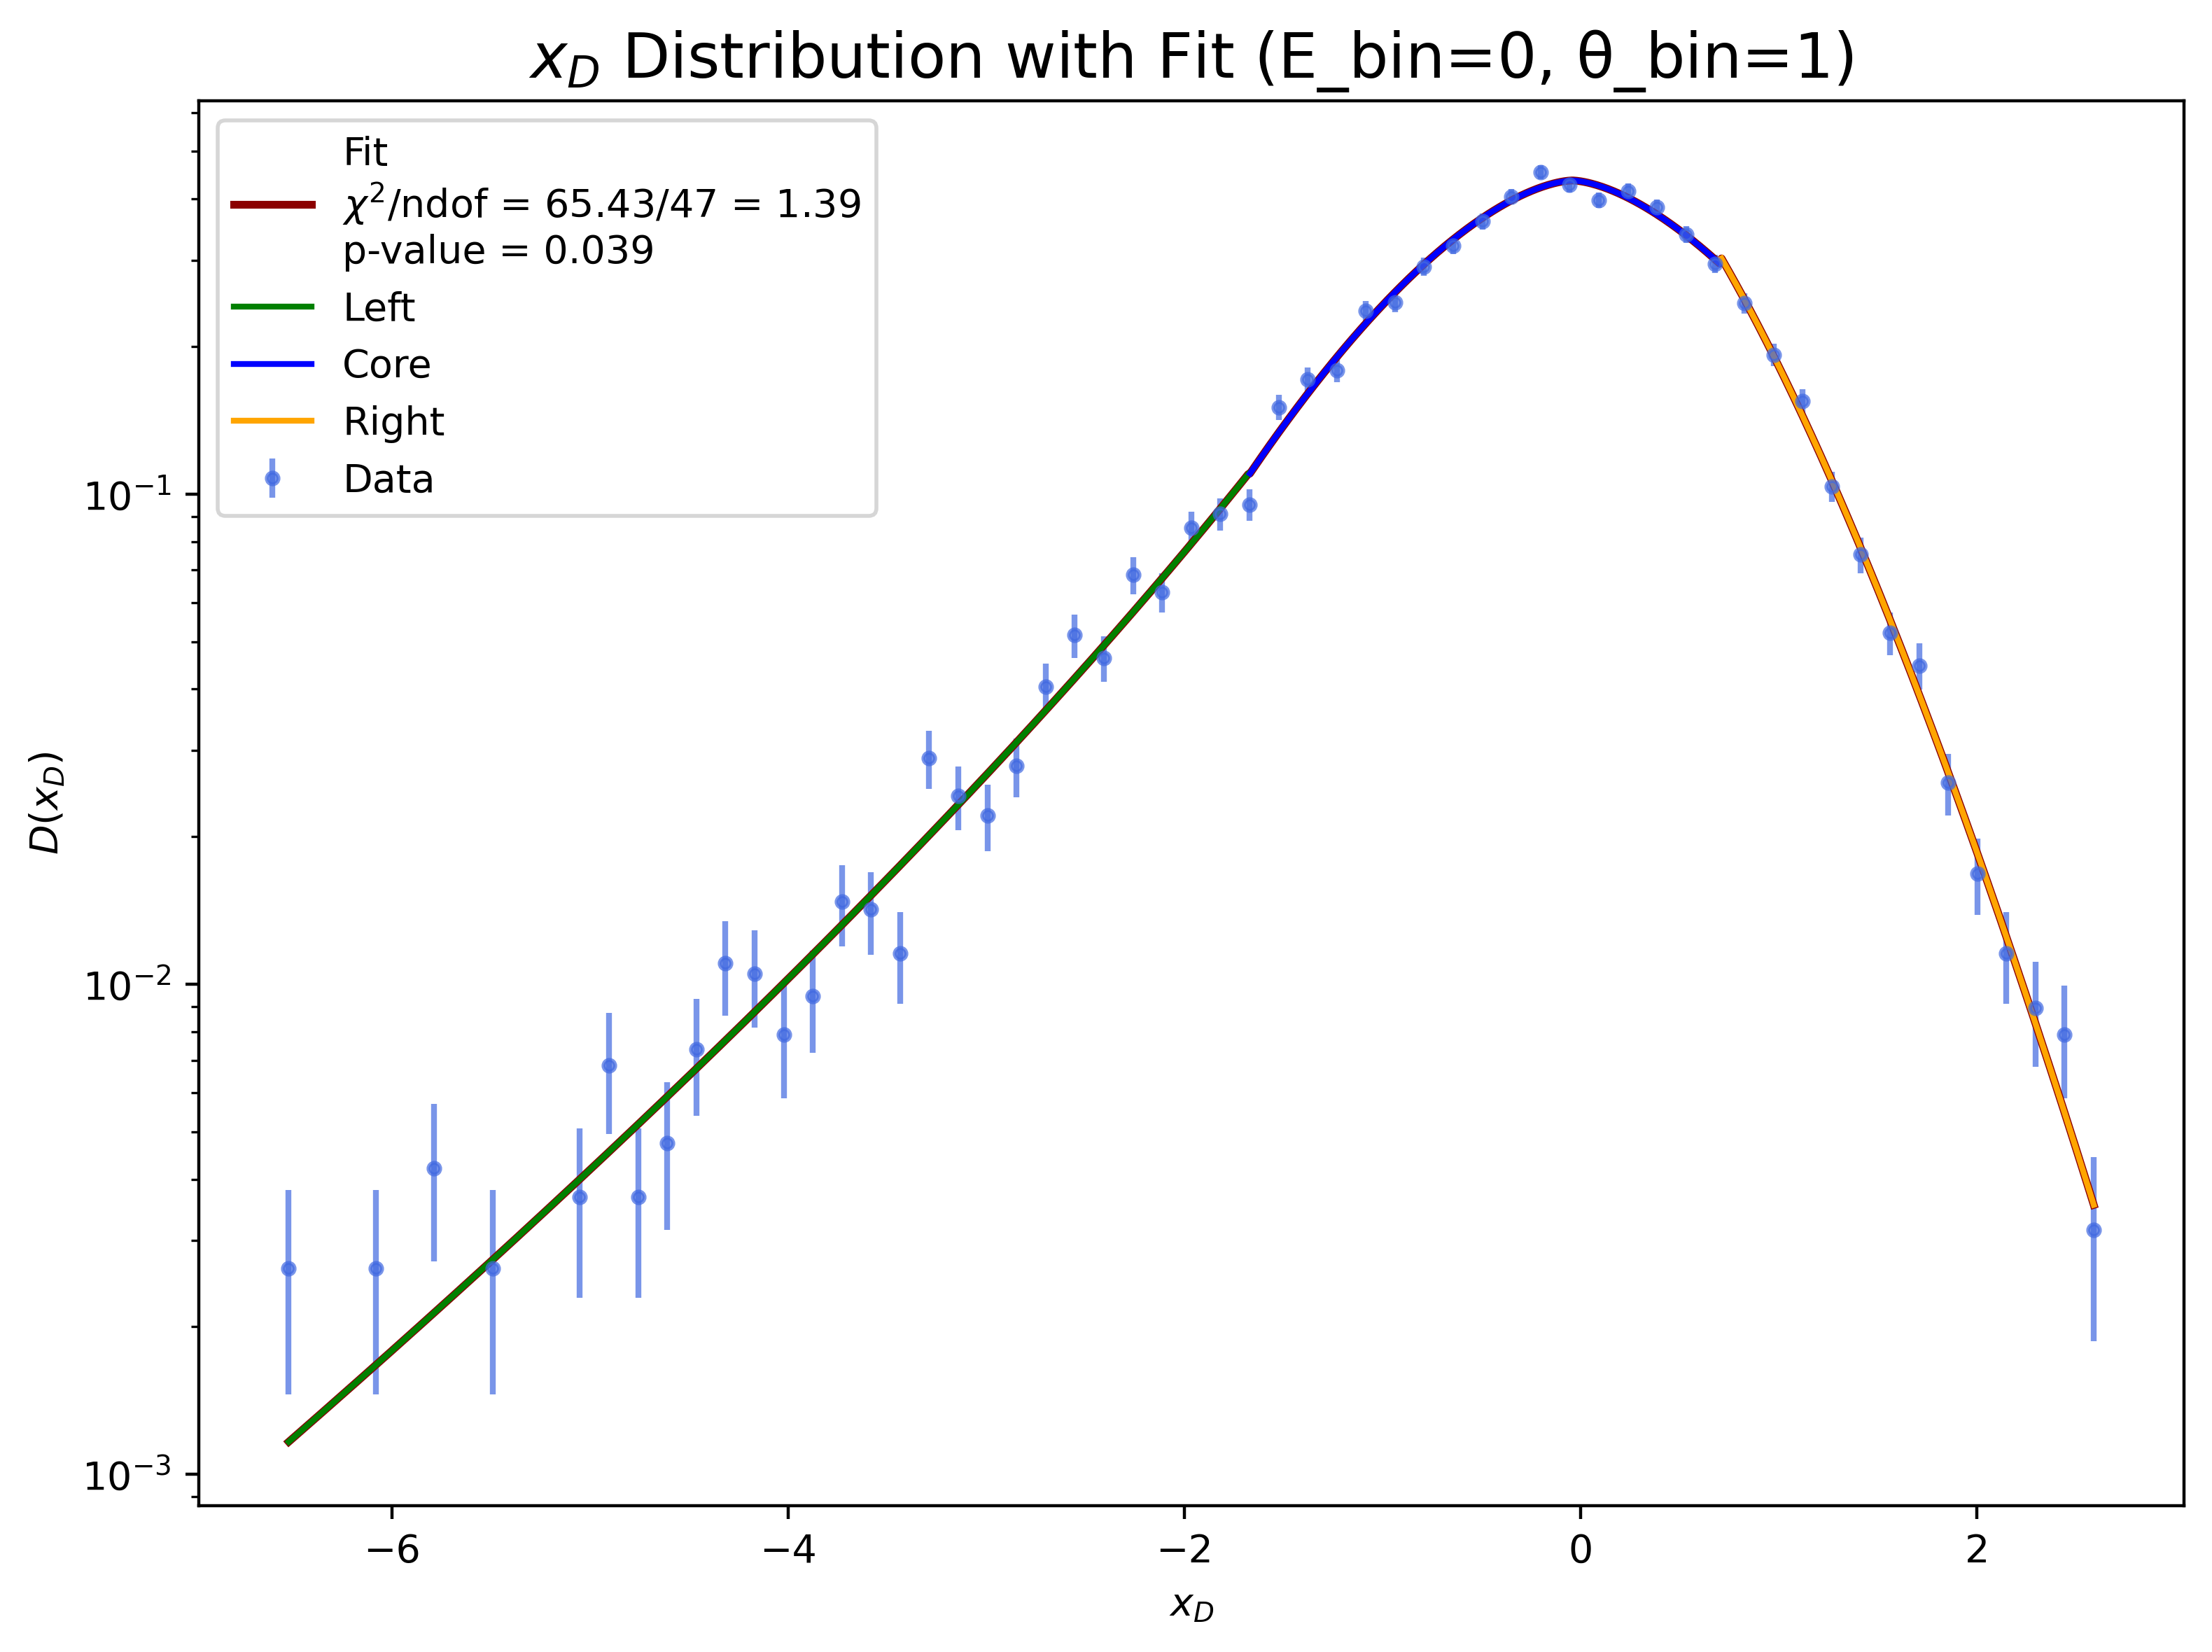

In [24]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.errorbar(bin_centers_masked, counts_norm_masked, yerr=errors_norm_masked, fmt='o', color='royalblue', alpha=0.7, label="Data", markersize=3)

if popt is not None:
    x_fit = np.linspace(np.min(bin_centers_masked), np.max(bin_centers_masked), 1000)
    y_fit = D(x_fit, *popt)
    ax.plot(x_fit, y_fit, color='darkred', lw=2, label=f'Fit\n{chi_squared_str}\n{prob_str}')
    # Optional: show components
    mask_L = x_fit - x0 < xbarL
    mask_I = (x_fit - x0 >= xbarL) & (x_fit - x0 <= xbarR)
    mask_R = x_fit - x0 > xbarR
    ax.plot(x_fit[mask_L], NL * R(x_fit[mask_L], x0, sigmaL, gammaL), color='green', label='Left')
    ax.plot(x_fit[mask_I], N * R(x_fit[mask_I], x0, sigmaI, gammaI), color='blue', label='Core')
    ax.plot(x_fit[mask_R], NR * R(x_fit[mask_R], x0, sigmaR, gammaR), color='orange', label='Right')


ax.set_title(f"$x_D$ Distribution with Fit (E_bin={E_bin}, θ_bin={theta_bin})", fontsize=16)
ax.set_xlabel("$x_D$")
ax.set_ylabel("$D(x_D)$")
ax.set_yscale('log')
ax.legend()
plt.tight_layout()
fig.savefig(figPath + f"x_D_fitE{E_bin}theta{theta_bin}.png", dpi=400)
plt.show()

### Step 2 : Plot all bins

In [25]:
class EmptyBinException(Exception):
    """Custom exception for empty bins."""
    pass

def fit_xd_bin(subset, n_bins=100, n_trials=100):
    counts, bin_edges = np.histogram(subset['x_D'], bins=n_bins)
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    bin_widths = bin_edges[1:] - bin_edges[:-1]
    errors = np.sqrt(counts)

    # Normalize counts and errors
    total = np.sum(counts)
    counts_norm = counts / (bin_widths * total)  
    errors_norm = errors / (bin_widths * total)  

    # Mask: counts > 5 and density > 10⁻³
    print("Number of bins before mask :", len(bin_centers))
    mask = (counts > 5) & (counts_norm > 0.001) & (errors_norm < 0.5*counts_norm)
    bin_centers_masked = bin_centers[mask]
    print("Number of bins remaining after mask :", len(bin_centers_masked))
    if len(bin_centers_masked) == 0:
        raise EmptyBinException("No bins remaining after masking. Fit cannot proceed.")
    counts_norm_masked = counts_norm[mask]
    errors_norm_masked = errors_norm[mask]

    # --- Bounds (to ensure positive widths and normalizations) ---
    #   x0, xbarL, xbarR, sigmaL, gammaL, sigmaI, gammaI, sigmaR, gammaR, NL, NI, NR
    bounds = (
        [-20, -15, -3,  0.001, 0.01,  1e-8, 0.01,  0.01, 0.4,  0],
        [ 20, 0, 1,  13,  10,  6, 10, 6, 10, 100]
    )

    norm_array = bin_widths[mask] * total

    # Fit
    try:
        popt, fit_vals, chi_squared = random_start_random_walk_fit(
        D,
        bin_centers_masked,
        counts_norm_masked,
        errors_norm_masked,
        bounds,
        norm_array,
        noise_scale=0.2,  # Increase if still stuck
        verbose=False,
        n_trials=n_trials,  # Increase if still stuck
    )

    except RuntimeError as e:
        print("Fit failed:", e)
        popt = None

    # Compute chi-squared
    
    ndof = len(bin_centers_masked) - len(popt)  # number of degrees of freedom
    p_value = 1 - chi2.cdf(chi_squared, ndof)


    return popt, chi_squared, p_value, bin_centers_masked, counts_norm_masked, errors_norm_masked



Processning E_bin=0, theta_bin=0
Number of bins before mask : 100
Number of bins remaining after mask : 36


/tmp/ipykernel_274178/249257967.py:12: RuntimeWarning: divide by zero encountered in scalar divide
  NR = N * R(xbarR, x0, sigmaI, gammaI) / R(xbarR, x0, sigmaR, gammaR)
/tmp/ipykernel_274178/249257967.py:12: RuntimeWarning: overflow encountered in scalar divide
  NR = N * R(xbarR, x0, sigmaI, gammaI) / R(xbarR, x0, sigmaR, gammaR)
/tmp/ipykernel_274178/249257967.py:16: RuntimeWarning: invalid value encountered in multiply
  D_vals[mask_R] = NR * R(x[mask_R], x0, sigmaR, gammaR)
/tmp/ipykernel_274178/249257967.py:11: RuntimeWarning: divide by zero encountered in scalar divide
  NL = N * R(xbarL, x0, sigmaI, gammaI) / R(xbarL, x0, sigmaL, gammaL)
/tmp/ipykernel_274178/249257967.py:14: RuntimeWarning: invalid value encountered in multiply
  D_vals[mask_L] = NL * R(x[mask_L], x0, sigmaL, gammaL)


New best value : χ² = 101.16


/tmp/ipykernel_274178/249257967.py:11: RuntimeWarning: invalid value encountered in scalar divide
  NL = N * R(xbarL, x0, sigmaI, gammaI) / R(xbarL, x0, sigmaL, gammaL)
/tmp/ipykernel_274178/249257967.py:11: RuntimeWarning: overflow encountered in scalar divide
  NL = N * R(xbarL, x0, sigmaI, gammaI) / R(xbarL, x0, sigmaL, gammaL)
/tmp/ipykernel_274178/249257967.py:12: RuntimeWarning: invalid value encountered in scalar divide
  NR = N * R(xbarR, x0, sigmaI, gammaI) / R(xbarR, x0, sigmaR, gammaR)


New best value : χ² = 74.14
New best value : χ² = 54.72
Best popt : [-1.16426558e+00 -2.83657125e-01 -3.04607355e-01  1.00039013e-03
  2.91741838e-01  6.89057075e-01  9.98542410e+00  1.76620116e+00
  4.79617960e+00  3.27423710e+01], len(opt) : 10
P-value :  0.0008242276434197171
Processning E_bin=0, theta_bin=1
Number of bins before mask : 100
Number of bins remaining after mask : 54
New best value : χ² = 83.41
New best value : χ² = 71.54
Best popt : [-0.04689907 -3.38780856 -0.61022822  1.12572382  1.25886536  0.6352026
  1.1711295   0.78626392  1.94270436  0.52070267], len(opt) : 10
P-value :  0.005403533941992111
Processning E_bin=0, theta_bin=2
Number of bins before mask : 100
Number of bins remaining after mask : 58
New best value : χ² = 46815.00
New best value : χ² = 33696.94
New best value : χ² = 59.67
Best popt : [ 0.09160697 -2.51825914 -0.570449    0.27905298  0.73753163  0.73351208
  1.37217908  0.8379679   1.90581956  0.47752762], len(opt) : 10
P-value :  0.1203047778362408

/cvmfs/sft.cern.ch/lcg/views/LCG_107/x86_64-el9-gcc14-opt/lib/python3.11/site-packages/scipy/optimize/_lsq/common.py:112: RuntimeWarning: overflow encountered in square
  denom = s**2 + alpha
/cvmfs/sft.cern.ch/lcg/views/LCG_107/x86_64-el9-gcc14-opt/lib/python3.11/site-packages/scipy/optimize/_lsq/common.py:161: RuntimeWarning: overflow encountered in square
  p = -V.dot(suf / (s**2 + alpha))
/cvmfs/sft.cern.ch/lcg/views/LCG_107/x86_64-el9-gcc14-opt/lib/python3.11/site-packages/scipy/optimize/_minpack_py.py:1044: RuntimeWarning: overflow encountered in square
  pcov = np.dot(VT.T / s**2, VT)


New best value : χ² = 717.49
Best popt : [ 6.70889271e-02 -3.32707456e+00 -1.84024335e-01  8.33320147e+00
  2.48333998e+00  6.49272814e-07  1.84442185e-01  1.59085335e-01
  2.05724421e+00  9.99999998e+01], len(opt) : 10
P-value :  0.0
Processning E_bin=3, theta_bin=4
Number of bins before mask : 100
Number of bins remaining after mask : 77
New best value : χ² = 276093.00
New best value : χ² = 1484.56
New best value : χ² = 672.51
New best value : χ² = 424.98
Best popt : [-3.07533714e-03 -3.23439291e+00  2.06184900e-01  1.00000209e-03
  2.34252387e-01  1.38784578e-05  2.26430214e-01  6.67690857e-01
  3.30800378e+00  4.89662107e+01], len(opt) : 10
P-value :  0.0


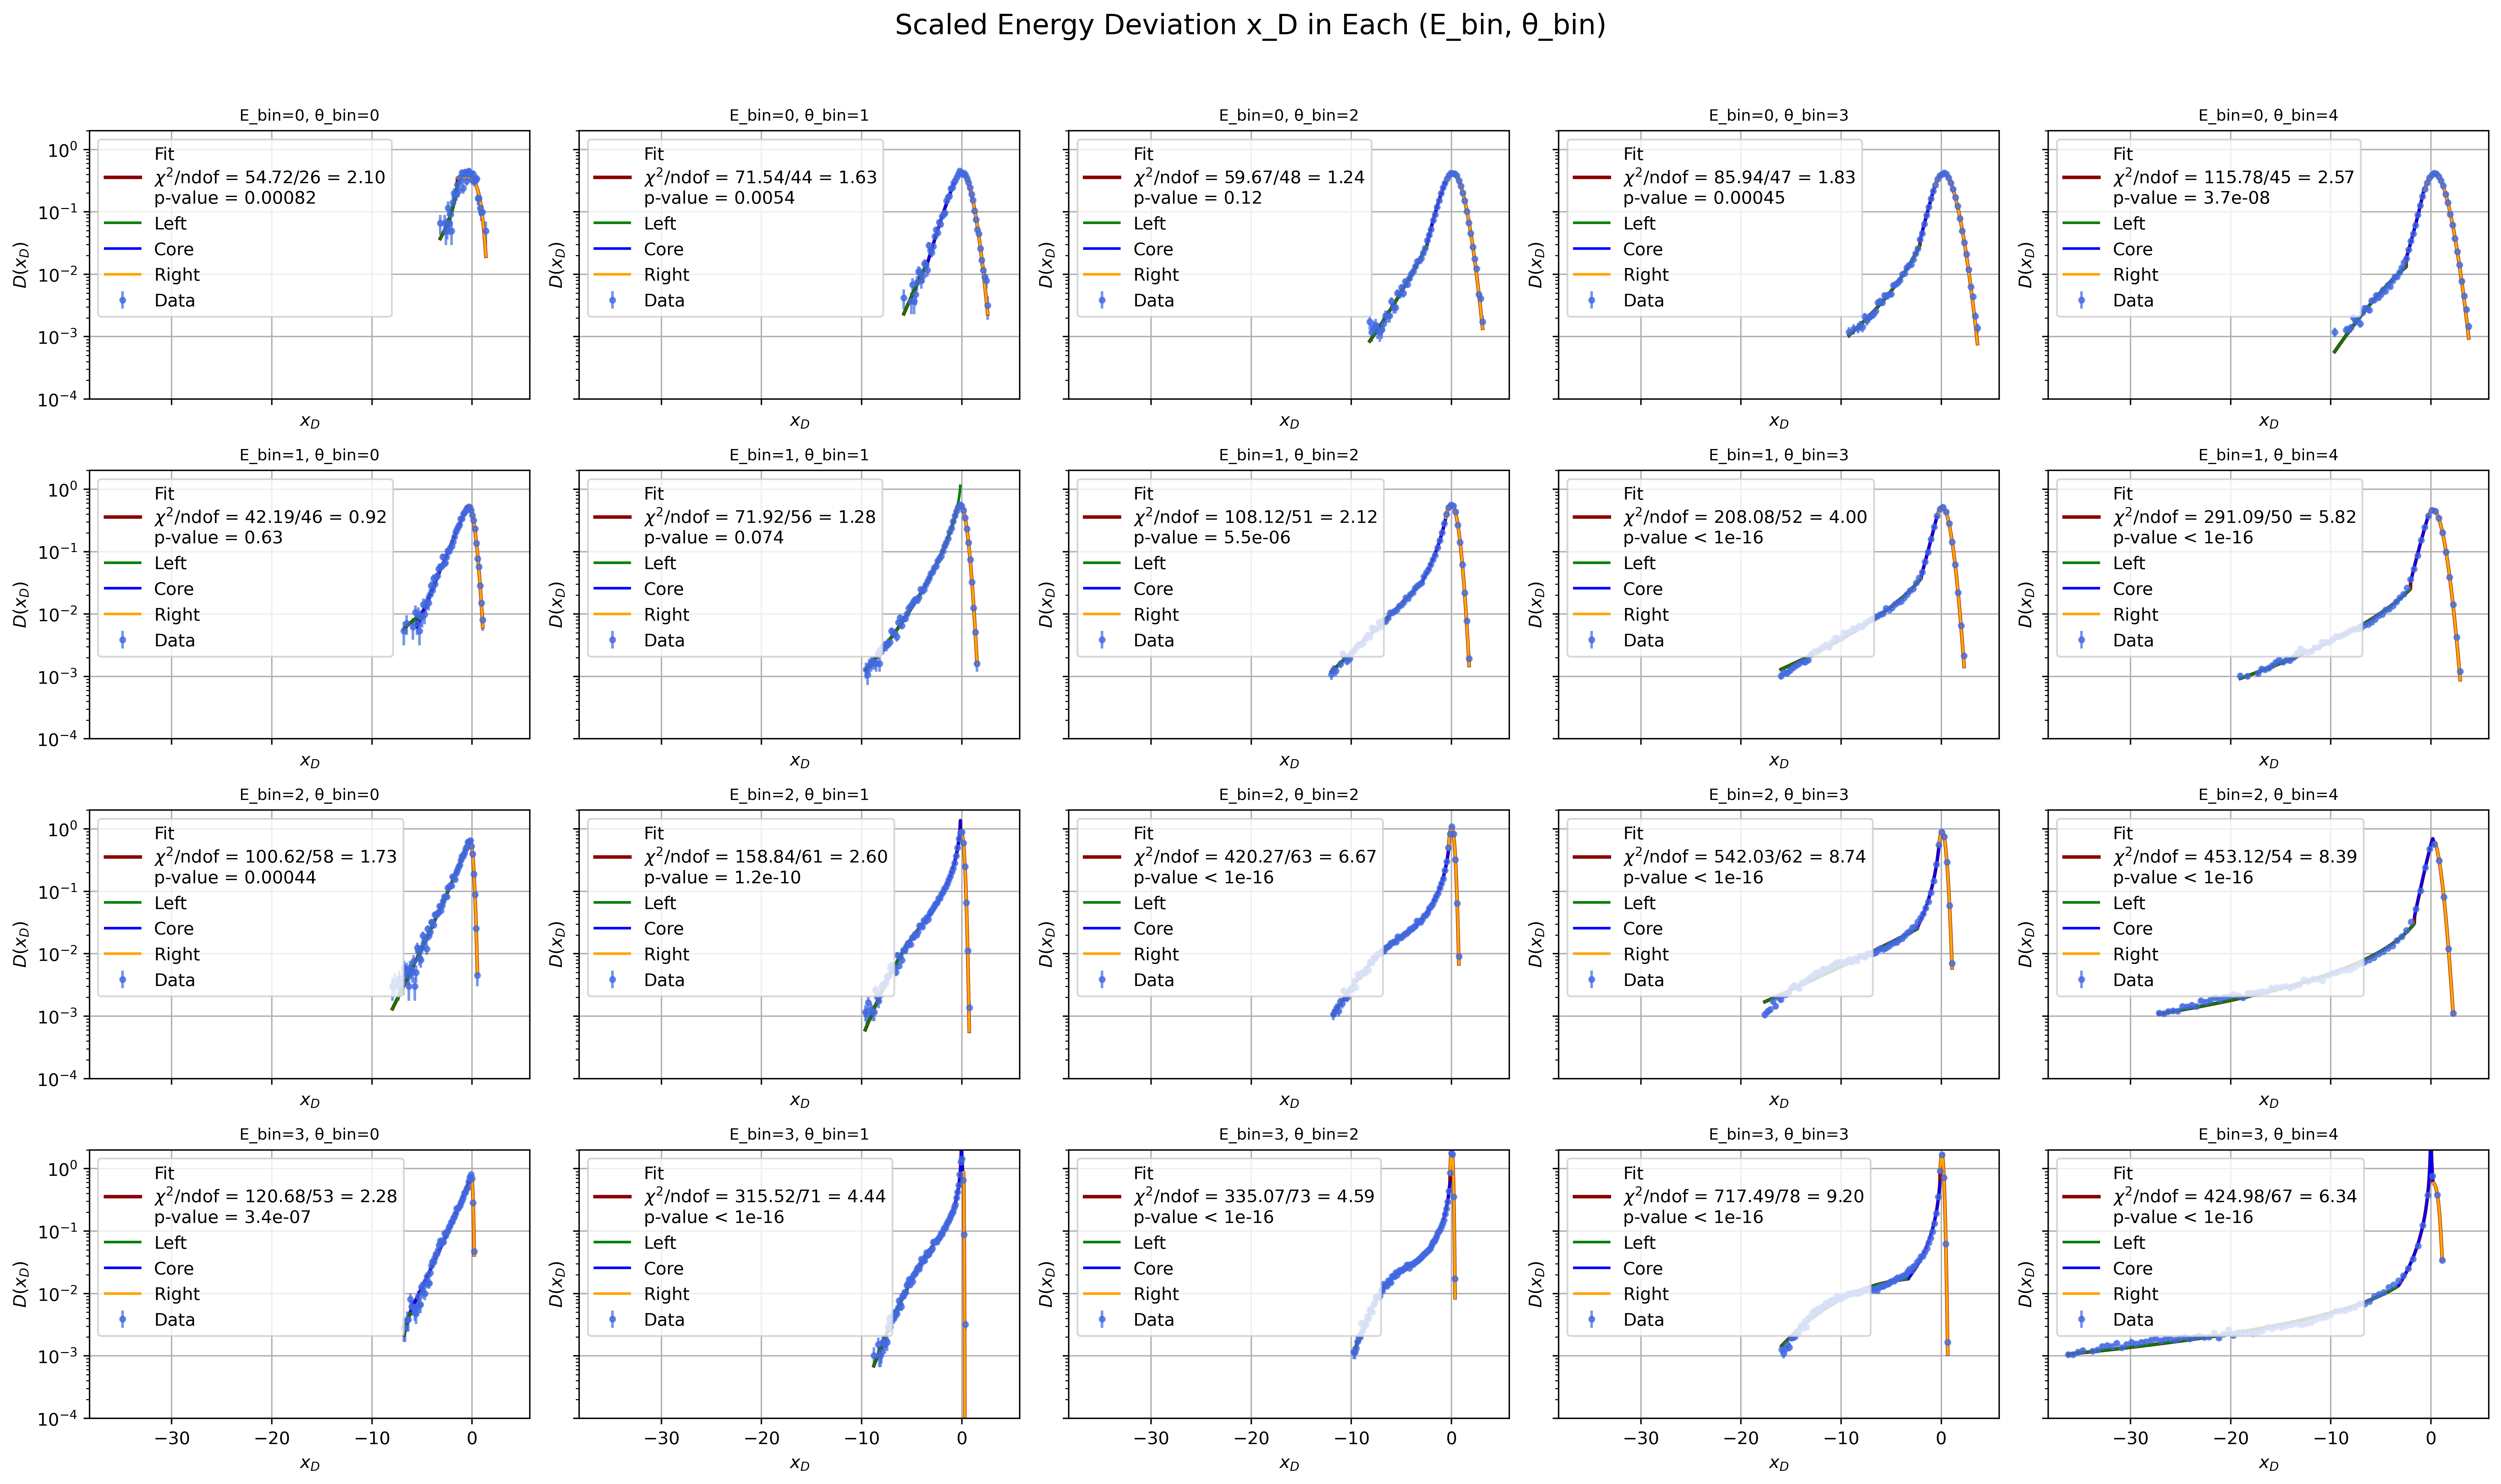

In [26]:
# Fit and Plot each bin
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 4, n_rows * 3), sharex=True, sharey=True)
fig.suptitle("Scaled Energy Deviation x_D in Each (E_bin, θ_bin)", fontsize=16)

for E_bin in range(n_E_bins):
    for theta_bin in range(n_theta_bins):
        print(f'Processning E_bin={E_bin}, theta_bin={theta_bin}')
        n_bins = 100
        subset = df[(df['E_bin'] == E_bin) & (df['theta_bin'] == theta_bin)]
        
        try:
            popt, chi_squared, p_value, bin_centers_masked, counts_norm_masked, errors_norm_masked = fit_xd_bin(subset, n_bins, n_trials = 30)
            print(f"Best popt : {popt}, len(opt) : {len(popt)}")
            np.save(resultPath + f"fit_params_LET_E{E_bin}_theta{theta_bin}.npy", popt)
        except EmptyBinException as e:
            print(e)
            popt = None
        # Save parameters


        if popt is not None:
            x0, xbarL, xbarR, sigmaL, gammaL, sigmaI, gammaI, sigmaR, gammaR, N = popt
            NL = N * R(xbarL, x0, sigmaI, gammaI) / R(xbarL, x0, sigmaL, gammaL)
            NR = N * R(xbarR, x0, sigmaI, gammaI) / R(xbarR, x0, sigmaR, gammaR)

            # Compute chi-squared
            ndof = len(bin_centers_masked) - len(popt)  # number of degrees of freedom

            chi_squared_str = f"$\chi^2$/ndof = {chi_squared:.2f}/{ndof} = {chi_squared/ndof:.2f}"
            print(f"P-value : ", p_value)
            if p_value < 1e-16:
                prob_str = "p-value < 1e-16"
            else:
                prob_str = f"p-value = {p_value:.2g}"

            ax = axes[E_bin, theta_bin]

            
            ax.errorbar(bin_centers_masked, counts_norm_masked, yerr=errors_norm_masked, fmt='o', color='royalblue', alpha=0.7, label="Data", markersize=3)
            ax.set_title(f"E_bin={E_bin}, θ_bin={theta_bin}", fontsize=9)
            
            x_fit = np.linspace(np.min(bin_centers_masked), np.max(bin_centers_masked), 1000)
            y_fit = D(x_fit, *popt)
            ax.plot(x_fit, y_fit, color='darkred', lw=2, label=f'Fit\n{chi_squared_str}\n{prob_str}')
            # Show components
            mask_L = x_fit - x0 < xbarL
            mask_I = (x_fit - x0 >= xbarL) & (x_fit - x0 <= xbarR)
            mask_R = x_fit - x0 > xbarR
            ax.plot(x_fit[mask_L], NL * R(x_fit[mask_L], x0, sigmaL, gammaL), color='green', label='Left')
            ax.plot(x_fit[mask_I], N * R(x_fit[mask_I], x0, sigmaI, gammaI), color='blue', label='Core')
            ax.plot(x_fit[mask_R], NR * R(x_fit[mask_R], x0, sigmaR, gammaR), color='orange', label='Right')


            ax.set_xlabel("$x_D$")
            ax.set_ylabel("$D(x_D)$")
            ax.set_yscale('log')
            ax.set_ylim(1e-4, 2)
            ax.grid()
            ax.legend()
        else:
            ax = axes[E_bin, theta_bin]
            ax.set_visible(False)
            print(f"Fit failed for E_bin={E_bin}, theta_bin={theta_bin}")


plt.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(figPath + "xD_allBins_fits.png", dpi=400)
plt.show()

In [27]:
fig.savefig(figPath + "xd_fit_all_bins.png", dpi=400)